# Level 1 - Task 3: Price Range Distribution

**Objective:**
1. Create a bar chart / histogram to visualize the distribution of price ranges.
2. Calculate the percentage of restaurants in each price range category.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')

print(f"✅ Dataset loaded!")
print(f"Total Restaurants: {len(df)}")
print(f"\nPrice Range column values:")
print(df['Price range'].value_counts().sort_index())

✅ Dataset loaded!
Total Restaurants: 9551

Price Range column values:
Price range
1    4444
2    3113
3    1408
4     586
Name: count, dtype: int64


In [2]:
# Count of restaurants in each price range
price_counts = df['Price range'].value_counts().sort_index()

# Percentage
price_percentages = (price_counts / len(df)) * 100

print("=" * 70)
print("💰 PRICE RANGE DISTRIBUTION")
print("=" * 70)
print(f"{'Price Range':<15} {'Count':<10} {'Percentage':<15}")
print("-" * 70)

# Labels for price ranges
labels = {
    1: "Budget (₹)",
    2: "Moderate (₹₹)",
    3: "Expensive (₹₹₹)",
    4: "Premium (₹₹₹₹)"
}

for price, count in price_counts.items():
    pct = price_percentages[price]
    print(f"{labels[price]:<15} {count:<10} {pct:>6.2f}%")
print("=" * 70)

# Most common price range
most_common = price_counts.idxmax()
print(f"\n🎯 Most Common Price Range: {labels[most_common]}")
print(f"   Restaurants: {price_counts[most_common]} ({price_percentages[most_common]:.2f}%)")

💰 PRICE RANGE DISTRIBUTION
Price Range     Count      Percentage     
----------------------------------------------------------------------
Budget (₹)      4444        46.53%
Moderate (₹₹)   3113        32.59%
Expensive (₹₹₹) 1408        14.74%
Premium (₹₹₹₹)  586          6.14%

🎯 Most Common Price Range: Budget (₹)
   Restaurants: 4444 (46.53%)


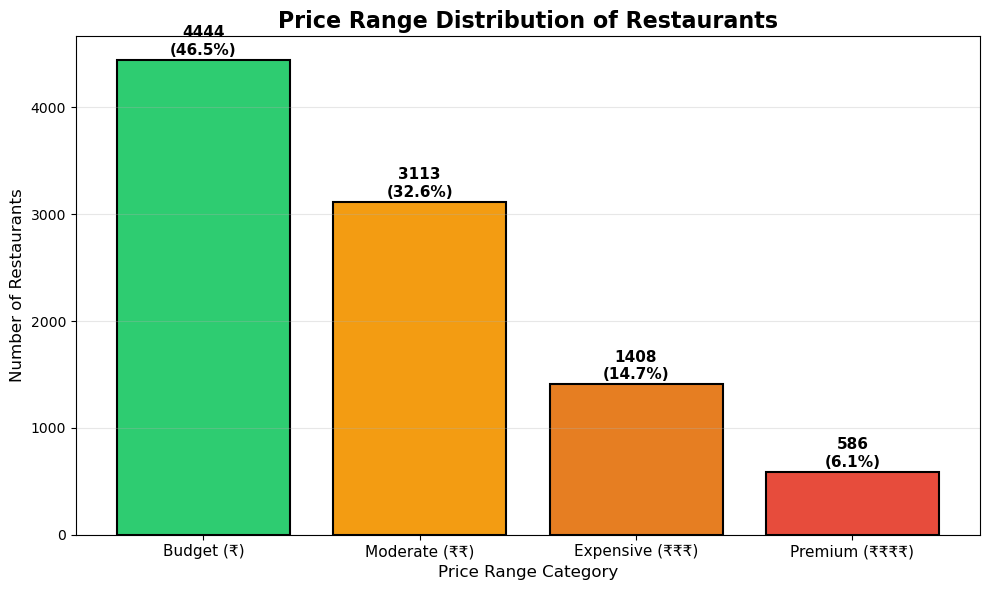

In [3]:
# Bar chart
plt.figure(figsize=(10, 6))

colors = ['#2ECC71', '#F39C12', '#E67E22', '#E74C3C']
bar_labels = [labels[p] for p in price_counts.index]

bars = plt.bar(bar_labels, price_counts.values, 
               color=colors, edgecolor='black', linewidth=1.5)


for bar, count, pct in zip(bars, price_counts.values, price_percentages.values):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 50,
             f'{count}\n({pct:.1f}%)', 
             ha='center', fontsize=11, fontweight='bold')

plt.title('Price Range Distribution of Restaurants', fontsize=16, fontweight='bold')
plt.xlabel('Price Range Category', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.xticks(fontsize=11)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

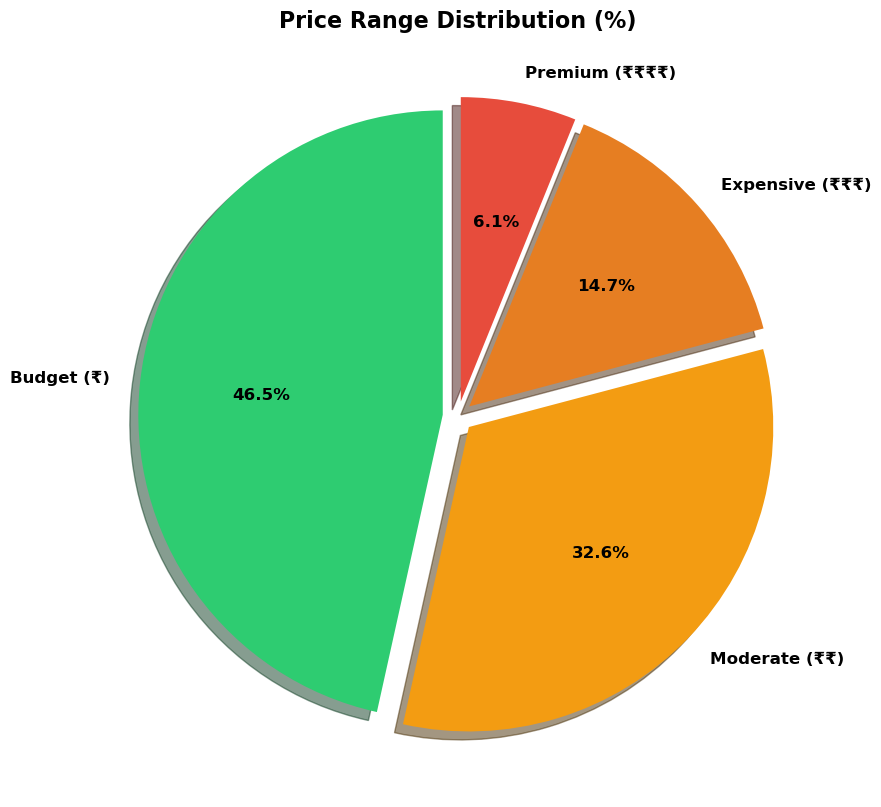

In [4]:
# Pie chart - percentage distribution
plt.figure(figsize=(9, 9))

plt.pie(price_counts.values,
        labels=[labels[p] for p in price_counts.index],
        autopct='%1.1f%%',
        colors=colors,
        startangle=90,
        explode=(0.05, 0.05, 0.05, 0.05),
        shadow=True,
        textprops={'fontsize': 12, 'fontweight': 'bold'})

plt.title('Price Range Distribution (%)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

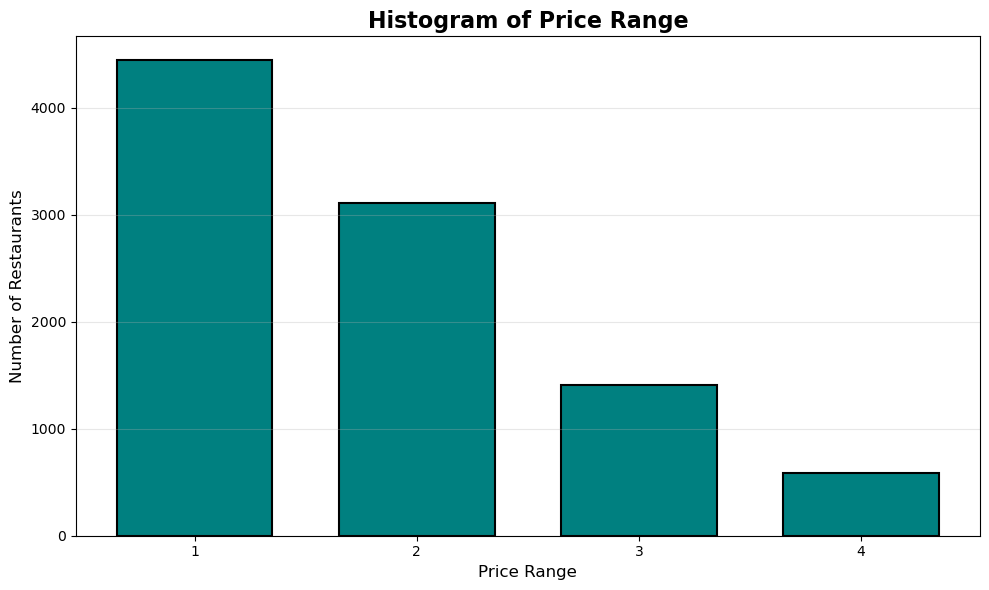

In [5]:
# Histogram 
plt.figure(figsize=(10, 6))

plt.hist(df['Price range'], bins=[0.5, 1.5, 2.5, 3.5, 4.5], 
         color='teal', edgecolor='black', linewidth=1.5, rwidth=0.7)

plt.title('Histogram of Price Range', fontsize=16, fontweight='bold')
plt.xlabel('Price Range', fontsize=12)
plt.ylabel('Number of Restaurants', fontsize=12)
plt.xticks([1, 2, 3, 4])
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Insights

### Price Range Distribution:
- **Moderate (₹₹)** is the most common price range with **X%** of restaurants.
- **Budget (₹)** has **Y%** — showing affordable options are also popular.
- **Expensive (₹₹₹)** accounts for **Z%** of restaurants.
- **Premium (₹₹₹₹)** is the least common with only **W%**.

### Key Observations:
1. The majority of restaurants fall in the **Moderate to Budget** category.
2. This suggests most restaurants target **middle-class and budget-conscious customers**.
3. Premium restaurants are rare — they serve a niche market.

### Conclusion:
- There's a clear pattern: as price range increases, restaurant count decreases.
- This indicates that the restaurant market is **dominated by affordable options**.